In [103]:
import numpy as np
import pandas as pd
import tensorflow as tf
import os
import time
import cv2
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from keras.models import Sequential
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, Dropout, Flatten
from keras import callbacks
from sklearn.metrics import classification_report, confusion_matrix



In [74]:
path_train = "../Data/dataset_yawn_eye/train"
path_test = "../Data/dataset_yawn_eye/test/"
path_haar_faces = "../Data/dataset_yawn_eye/haarcascade/haarcascade_frontalface_default.xml"

labels = os.listdir(path_train)
labels.remove(".DS_Store")
labels

IMG_SIZE = (145, 145)


### Import and resize image-data

In [75]:

def load_data(path_data):
    X = []
    y = []

    for label in os.listdir(path_data):
        if not label.startswith('.'): # exclude ".DS_Store"-files (MacOS-specific)
            path = os.path.join(path_data, label)
            label_index = labels.index(label)
            print(label)

            for file in os.listdir(path):
                if not file.startswith('.'):
                    img_matrix = cv2.imread(os.path.join(path, file), cv2.IMREAD_GRAYSCALE)

                    # get rid of all background if complete faces
                    if label in ["no_yawn", "yawn"]:
                        face_cascade = cv2.CascadeClassifier(path_haar_faces)
                        found_faces = face_cascade.detectMultiScale(img_matrix, 1.3, 5)
                        

                        for (x_pos, y_pos, width, height) in found_faces:
                            img = cv2.rectangle(img_matrix, (x_pos, y_pos, width, height), (0, 255, 0), 2)

                            # get region of interest (only face)
                            img_matrix = img[y_pos : y_pos + height, x_pos : x_pos + width]
                    
                    try:
                        img_final = cv2.resize(img_matrix, IMG_SIZE)

                        X.append(img_final)
                        y.append(label_index)

                    except Exception as e:
                        print(e)
    return X, y



In [76]:
x_train, y_train = load_data(path_train)
x_test, y_test = load_data(path_test)


print("x_train len: ", len(x_train))
print("y_train len: ", len(y_train))
print(f'labels : {list(set(y_train))}')
print(f'x_train-shape: ({ len(x_train) }, { len(x_train[0]) }, { len(x_train[0][0]) })')

print("Testdaten:")
print("x_train len: ", len(x_train))
print("y_train len: ", len(y_train))
print(f'labels : {list(set(y_train))}')
print(f'x_train-shape: ({ len(x_train) }, { len(x_train[0]) }, { len(x_train[0][0]) })')

Closed
no_yawn
OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

yawn
OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

OpenCV(4.7.0) /Users/xperience/GHA-OCV-Python/_work/opencv-python/opencv-python/opencv/modules/imgproc/src/resize.cpp:4062: error: (-215:Assertion failed) !ssize.empty() in function 'resize'

Open
Closed
no_yawn


#### Save image-data to binary files

In [77]:
npx = np.array(x_train)
dfx = pd.DataFrame(npx.reshape((npx.shape[0], npx.shape[1] * npx.shape[2])))

npy = np.array(y_train)
dfy = pd.DataFrame(npy)

dfx.to_csv("../Data/dataset_yawn_eye/preprocessed/x_train.csv")
dfy.to_csv("../Data/dataset_yawn_eye/preprocessed/y_train.csv")

npx = np.array(x_test)
dfx = pd.DataFrame(npx.reshape((npx.shape[0], npx.shape[1] * npx.shape[2])))

npy = np.array(y_test)
dfy = pd.DataFrame(npy)

dfx.to_csv("../Data/dataset_yawn_eye/preprocessed/x_test.csv")
dfy.to_csv("../Data/dataset_yawn_eye/preprocessed/y_test.csv")

### Read preprocessed CSV-data

In [105]:

def read_all_csv_data():
    path_x_csv = "../Data/dataset_yawn_eye/preprocessed/x_train.csv"
    path_y_csv = "../Data/dataset_yawn_eye/preprocessed/y_train.csv"
    path_x_csv_test = "../Data/dataset_yawn_eye/preprocessed/x_test.csv"
    path_y_csv_test = "../Data/dataset_yawn_eye/preprocessed/y_test.csv"

    x_read = pd.read_csv(path_x_csv, index_col = 0)
    y_read = pd.read_csv(path_y_csv, index_col = 0)
    x_read_test = pd.read_csv(path_x_csv_test, index_col = 0)
    y_read_test = pd.read_csv(path_y_csv_test, index_col = 0)

    x_train = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_train = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    x_test = x_read.values.reshape((len(x_read.index), IMG_SIZE[0], IMG_SIZE[1]))
    y_test = np.array(y_read).reshape(np.array(y_read).shape[0]).tolist()

    del x_read
    del y_read
    del x_read_test
    del y_read_test

    return x_train, x_test, y_train, y_test

x_train, x_test, y_train, y_test = read_all_csv_data()

### Print sample images for each label

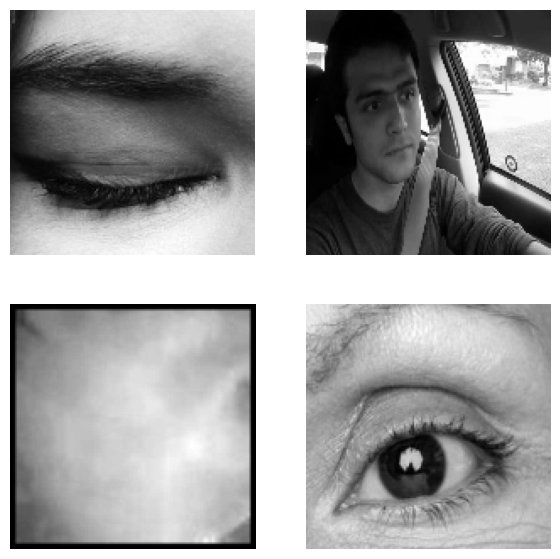

In [106]:
y_set = set(y_train)
y_set_idx = 0

fig = plt.figure(figsize=(7, 7))
fig_axes = fig.subplots(2, 2)


for i in range(2):
    for j in range(2):
        img = x_train[y_train.index(list(y_set)[y_set_idx])]

        fig_axes[i, j].imshow(img, "gray")
        fig_axes[i, j].axis("off")

        y_set_idx += 1


fig.savefig("../imgs/labels.svg")

In [107]:
# normalize data
x_train = x_train.reshape((x_train.shape[0], x_train.shape[1] * x_train.shape[2]))
x_train = x_train.astype(float) / 255
x_test = x_test.reshape((x_test.shape[0], x_test.shape[1] * x_test.shape[2]))
x_test = x_test.astype(float) / 255

encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train)
y_test = encoder.fit_transform(y_test)

### Create and train simple MLP model

In [118]:
model_mlp = Sequential()
model_mlp.add(Input(shape=(IMG_SIZE[0] * IMG_SIZE[1],)))
model_mlp.add(Dense(512, activation="relu"))
model_mlp.add(Dense(256, activation="relu"))
model_mlp.add(Dense(256, activation="relu"))
model_mlp.add(Dense(len(set(y_train)), activation="softmax"))

model_mlp.summary()

model_mlp.compile(
    optimizer = "adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), 
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy()]
)

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_44 (Dense)            (None, 512)               10765312  
                                                                 
 dense_45 (Dense)            (None, 256)               131328    
                                                                 
 dense_46 (Dense)            (None, 256)               65792     
                                                                 
 dense_47 (Dense)            (None, 4)                 1028      
                                                                 
Total params: 10963460 (41.82 MB)
Trainable params: 10963460 (41.82 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [119]:
# early stopping callback

early_stopping = callbacks.EarlyStopping(
    monitor = "val_loss",
    min_delta = 0.03,
    patience = 3,
    restore_best_weights = True
)

In [120]:
# training of MLP
timer_start = time.time()

history = model_mlp.fit(
    x = x_train,
    y = y_train,
    validation_data = (x_test, y_test),
    callbacks = [early_stopping],
    epochs = 10
)

timer_end = time.time()

print('\nGesamtlaufzeit: {:5.2f}s'.format(timer_end - timer_start))

Epoch 1/10
77/77 [==============================] - 3s 31ms/step - loss: 2.0173 - sparse_categorical_accuracy: 0.5118 - val_loss: 0.6799 - val_sparse_categorical_accuracy: 0.6454
Epoch 2/10
77/77 [==============================] - 2s 26ms/step - loss: 0.5785 - sparse_categorical_accuracy: 0.7315 - val_loss: 0.5029 - val_sparse_categorical_accuracy: 0.7364
Epoch 3/10
77/77 [==============================] - 2s 26ms/step - loss: 0.5370 - sparse_categorical_accuracy: 0.7526 - val_loss: 0.7876 - val_sparse_categorical_accuracy: 0.6669
Epoch 4/10
77/77 [==============================] - 2s 26ms/step - loss: 0.5960 - sparse_categorical_accuracy: 0.7291 - val_loss: 0.4137 - val_sparse_categorical_accuracy: 0.8245
Epoch 5/10
77/77 [==============================] - 2s 26ms/step - loss: 0.5067 - sparse_categorical_accuracy: 0.7701 - val_loss: 0.4073 - val_sparse_categorical_accuracy: 0.8225
Epoch 6/10
77/77 [==============================] - 2s 26ms/step - loss: 0.4519 - sparse_categorical_accu

In [125]:
predictions = model_mlp.predict(x_test)
y_pred = []

for i in predictions:
    y_pred.append(np.array(i).argmax())


y_test_transformed = encoder.inverse_transform(y_test)
y_pred_transformed = encoder.inverse_transform(y_pred)

mlp_report = classification_report(y_test_transformed, y_pred_transformed)

print(mlp_report)

77/77 [==============================] - 1s 7ms/step
[0 0 0 ... 3 3 3]
2462
